Accuracy with k=5: 97.78%
New sample [5.1, 3.5, 1.4, 0.2] -> setosa


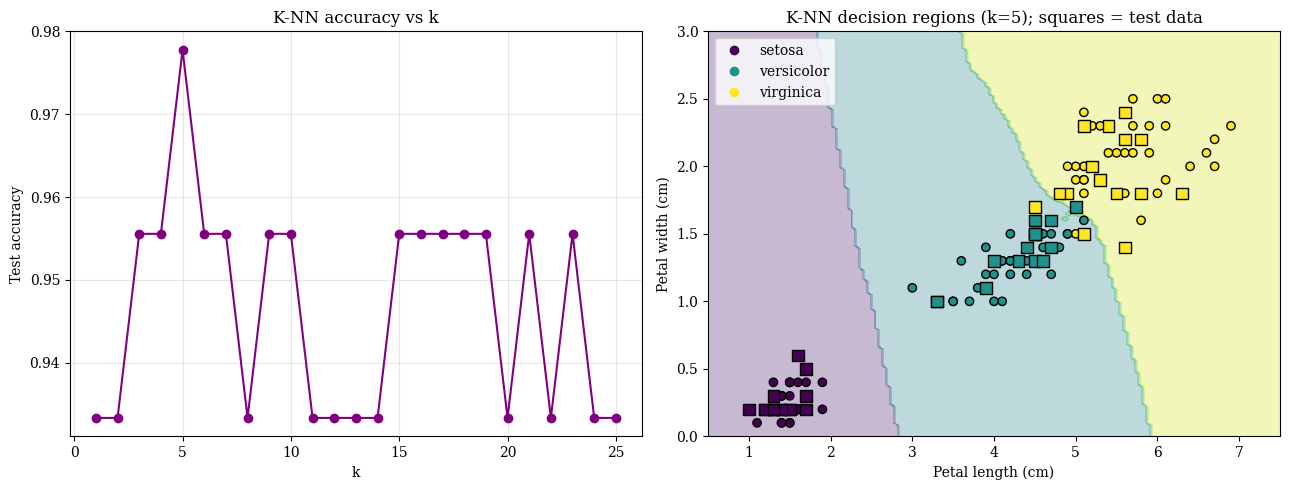

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

plt.rcParams["font.family"] = "serif"

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
Xi, yi = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(Xi, yi, test_size=0.3, random_state=42, stratify=yi)

def knn_predict(X_train, y_train, X_new, k):
    preds = []
    for x in np.atleast_2d(X_new):
        d = np.sqrt(((X_train - x) ** 2).sum(axis=1))   # Euclidean distances
        nearest = y_train[np.argsort(d)[:k]]             # labels of k nearest
        preds.append(Counter(nearest).most_common(1)[0][0])
    return np.array(preds)

k = 5
acc = (knn_predict(X_train, y_train, X_test, k) == y_test).mean()
print(f"Accuracy with k={k}: {acc*100:.2f}%")

sample = [5.1, 3.5, 1.4, 0.2]
print("New sample", sample, "->", iris.target_names[knn_predict(X_train, y_train, sample, k)[0]])

# ---- Graph 1: accuracy for different k
ks = range(1, 26)
accs = [(knn_predict(X_train, y_train, X_test, kk) == y_test).mean() for kk in ks]

# ---- Graph 2: decision regions using petal length & width
Xp = Xi[:, 2:4]
Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(Xp, yi, test_size=0.3, random_state=42, stratify=yi)
xx, yy = np.meshgrid(np.linspace(0.5, 7.5, 150), np.linspace(0, 3, 150))
zz = knn_predict(Xp_tr, yp_tr, np.c_[xx.ravel(), yy.ravel()], k).reshape(xx.shape)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(list(ks), accs, "o-", color="purple")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Test accuracy"); ax[0].set_title("K-NN accuracy vs k"); ax[0].grid(alpha=.3)
ax[1].contourf(xx, yy, zz, alpha=.3, cmap="viridis")
sc = ax[1].scatter(Xp_tr[:,0], Xp_tr[:,1], c=yp_tr, cmap="viridis", edgecolors="k", label="train")
ax[1].scatter(Xp_te[:,0], Xp_te[:,1], c=yp_te, cmap="viridis", edgecolors="k", marker="s", s=70)
ax[1].set_xlabel("Petal length (cm)"); ax[1].set_ylabel("Petal width (cm)")
ax[1].set_title(f"K-NN decision regions (k={k}); squares = test data")
handles = [plt.Line2D([], [], marker="o", ls="", color=sc.cmap(sc.norm(i)), label=n) for i, n in enumerate(iris.target_names)]
ax[1].legend(handles=handles)
plt.tight_layout(); plt.show()